In [1]:
import netCDF4 as nc
import glob
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import xrft
from scipy.io import loadmat
import scipy.io as sio
from scipy.special import gamma, kv
from numpy.linalg import inv
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import pyplot as plt, animation
import h5py
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import mpmath as mp
import datetime
from matplotlib import pyplot as plt, animation
import scipy.stats as stats
import pandas as pd
import math
import pickle
import zipfile
import matplotlib
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker

plt.rc("axes", titlesize="medium")
# matplotlib.style.use("petroff10")

figscale = 1.4


In [2]:
with open('data/GSExtension_reselect_sim.pkl', 'rb') as f:
    data_GS = pickle.load(f)

In [3]:
with open('data/Oleander_reselect_sim.pkl', 'rb') as f:
    data_Ol = pickle.load(f)

In [4]:
spectra_tot_combined_GS = data_GS['spectra_tot_combined'] # spectra from SWOT
ssha_tot_combined_GS    = data_GS['ssha_tot_combined'] # ssh fields (two swaths) from SWOT and simulation spectra
lon_strip_tot_GS        = data_GS['lon_strip_tot']# SWOT longitude
lat_strip_tot_GS        = data_GS['lat_strip_tot']# SWOT latitude

In [5]:
spectra_tot_combined_Ol = data_Ol['spectra_tot_combined']# spectral from SWOT
ssha_tot_combined_Ol    = data_Ol['ssha_tot_combined'] # ssh fields (two swaths) from SWOT and simulation spectra 
lon_strip_tot_Ol        = data_Ol['lon_strip_tot']# SWOT longitude
lat_strip_tot_Ol        = data_Ol['lat_strip_tot']# SWOT latitude

## Figure 1 study domain 


In [6]:
NA_simulation = np.load('data/NA_RV_snapshot.npy',allow_pickle='TRUE').item() # load relative vorticity computed in the simulation 

In [7]:
for key, value in NA_simulation.items():
    globals()[key] = value

In [8]:
f_inertial = 2*np.pi*np.sin(2*np.pi*yc[1:,1:]/360)/(12*3600)  

In [19]:
print(lon_w,lon_e,lat_s,lat_n)

-70 -60 30 35


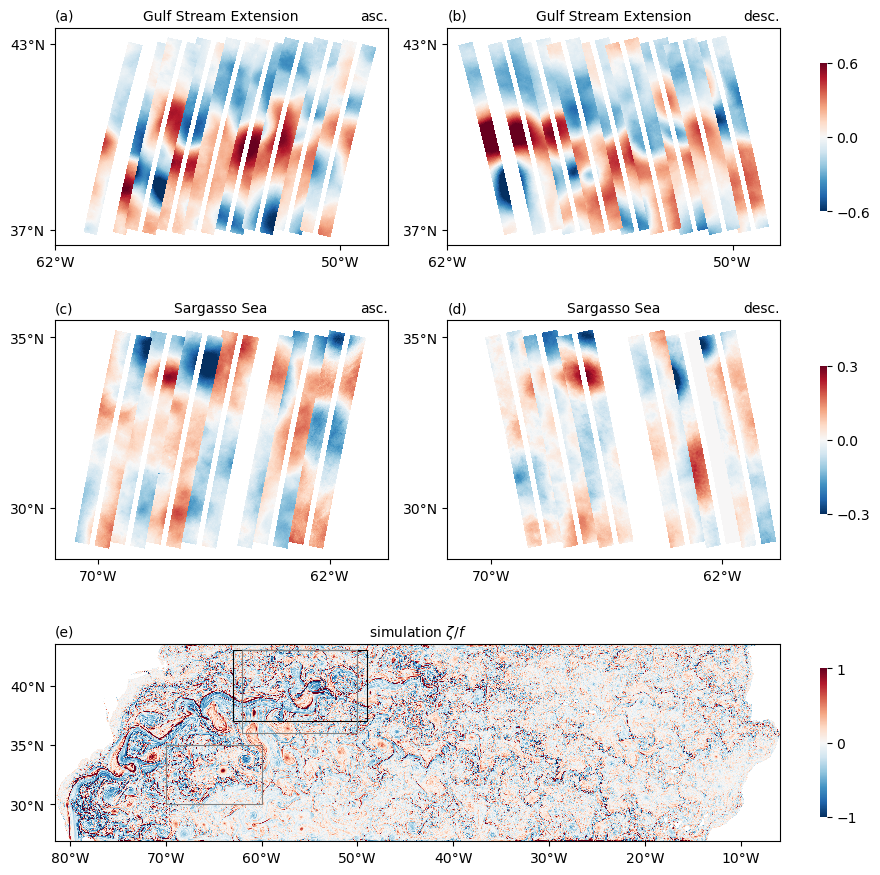

In [23]:
fig = plt.figure(figsize=(figscale*6.5, figscale*6.5))

# 3 rows, 2 columns
gs = gridspec.GridSpec(
    3, 3,
    figure=fig,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 0.02]
)


extent_gs = [-62, -48, 36.5, 43.5]
extent_ss = [-71.5, -60, 28.5, 35.5]

extent_gs_sim = [-63, -49, 37, 43]


vmax_gs = 0.6
vmax_ss = 0.3

# top left
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_aspect(1/np.cos(np.pi/180*(extent_gs[2] + extent_gs[3])/2))
# plot ascending swaths for Gulf Stream extension 
plt.pcolormesh(lon_strip_tot_GS[2], lat_strip_tot_GS[2], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==89].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[4], lat_strip_tot_GS[4], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==117].iloc[3]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[6], lat_strip_tot_GS[6], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==145].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[8], lat_strip_tot_GS[8], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==173].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[11], lat_strip_tot_GS[11], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==367].iloc[6]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[13], lat_strip_tot_GS[13], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==395].iloc[1]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[15], lat_strip_tot_GS[15], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==423].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[17], lat_strip_tot_GS[17], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==451].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[19], lat_strip_tot_GS[19], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==479].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
ax1.set_xlim(extent_gs[0] + 360, extent_gs[1] + 360)
ax1.set_ylim(extent_gs[2], extent_gs[3])
ax1.set_xticks([298, 310], ["62°W", "50°W"])
ax1.set_yticks([37, 43], ["37°N", "43°N"])
ax1.set_title('(a)',loc = 'left')
ax1.set_title('Gulf Stream Extension')
ax1.set_title('asc.', loc="right")

# top right
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_aspect(1/np.cos(np.pi/180*(extent_gs[2] + extent_gs[3])/2))
# plot descending swaths for Gulf Stream extension
plt.pcolormesh(lon_strip_tot_GS[0], lat_strip_tot_GS[0], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==46].iloc[1]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[1], lat_strip_tot_GS[1], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==74].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[3], lat_strip_tot_GS[3], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==102].iloc[1]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[5], lat_strip_tot_GS[5], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==130].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[7], lat_strip_tot_GS[7], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==158].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[10], lat_strip_tot_GS[10], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==352].iloc[1]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[12], lat_strip_tot_GS[12], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==380].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[14], lat_strip_tot_GS[14], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==408].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_GS[16], lat_strip_tot_GS[16], ssha_tot_combined_GS[ssha_tot_combined_GS['position']==436].iloc[0]['ssha2side'],vmin=-vmax_gs,vmax=vmax_gs ,rasterized=True, cmap="RdBu_r")
ax2.set_xlim(extent_gs[0] + 360, extent_gs[1] + 360)
ax2.set_ylim(extent_gs[2], extent_gs[3])
ax2.set_xticks([298, 310], ["62°W", "50°W"])
ax2.set_yticks([37, 43], ["37°N", "43°N"])
ax2.set_title('(b)',loc = 'left')
ax2.set_title('Gulf Stream Extension')
ax2.set_title('desc.', loc="right")
# plt.colorbar(pad = 0.02,fraction = 0.02)

cax1 = fig.add_subplot(gs[0,2])
cb1 = plt.colorbar(cax=cax1, ticks=[-vmax_gs, 0, vmax_gs])
cb1.outline.set_visible(False)

# middle left
ax3 = fig.add_subplot(gs[1, 0])
ax3.set_aspect(1/np.cos(np.pi/180*(extent_ss[2] + extent_ss[3])/2))
# plot ascending swaths for Sargasso Sea
plt.pcolormesh(lon_strip_tot_Ol[0], lat_strip_tot_Ol[0], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==201].iloc[4]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[2], lat_strip_tot_Ol[2], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==229].iloc[6]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[4], lat_strip_tot_Ol[4], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==257].iloc[2]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[6], lat_strip_tot_Ol[6], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==479].iloc[2]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[8], lat_strip_tot_Ol[8], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==507].iloc[0]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[10], lat_strip_tot_Ol[10], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==535].iloc[0]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[12], lat_strip_tot_Ol[12], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==563].iloc[0]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
ax3.set_xlim(extent_ss[0] + 360, extent_ss[1] + 360)
ax3.set_ylim(extent_ss[2], extent_ss[3])
ax3.set_xticks([290, 298], ["70°W", "62°W"])
ax3.set_yticks([30, 35], ["30°N", "35°N"])
ax3.set_title('(c)',loc = 'left')
ax3.set_title('Sargasso Sea')
ax3.set_title('asc.', loc="right")

# middle right
ax4 = fig.add_subplot(gs[1, 1])
ax4.set_aspect(1/np.cos(np.pi/180*(extent_ss[2] + extent_ss[3])/2))
# plot descending swaths for Sargasso Sea 
plt.pcolormesh(lon_strip_tot_Ol[1], lat_strip_tot_Ol[1], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==214].iloc[10]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[5], lat_strip_tot_Ol[5], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==270].iloc[1]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[7], lat_strip_tot_Ol[7], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==492].iloc[2]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[9], lat_strip_tot_Ol[9], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==520].iloc[0]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[11], lat_strip_tot_Ol[11], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==548].iloc[1]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
plt.pcolormesh(lon_strip_tot_Ol[13], lat_strip_tot_Ol[13], ssha_tot_combined_Ol[ssha_tot_combined_Ol['position']==576].iloc[3]['ssha2side'],vmin=-vmax_ss,vmax=vmax_ss,rasterized=True, cmap="RdBu_r")
ax4.set_xlim(extent_ss[0] + 360, extent_ss[1] + 360)
ax4.set_ylim(extent_ss[2], extent_ss[3])
ax4.set_xticks([290, 298], ["70°W", "62°W"])
ax4.set_yticks([30, 35], ["30°N", "35°N"])
ax4.set_title('(d)',loc = 'left')
ax4.set_title('Sargasso Sea')
ax4.set_title('desc.', loc="right")

cax2 = fig.add_subplot(gs[1,2])
cb2 = plt.colorbar(cax=cax2, ticks=[-vmax_ss, 0, vmax_ss])
cb2.outline.set_visible(False)

# bottom spans both columns, with map projection
ax5 = fig.add_subplot(gs[2,0:2])
cl = plt.pcolormesh(xc, yc, RV/f_inertial, vmin=-1, vmax=1, cmap='RdBu_r',rasterized=True)
ax5.set_aspect(1/np.cos(36*np.pi/180))

ax5.set_xticks(np.arange(-80, -9, 10))
ax5.set_yticks(np.arange(30, 41, 5))
ax5.set_xticklabels([r"80°W", r"70°W", r"60°W", r"50°W",r"40°W",r"30°W",r"20°W",r"10°W"])
ax5.set_yticklabels([r"30°N", r"35°N", r"40°N"])

# model boxes
lon_w, lon_e, lat_s, lat_n = -70, -60, 30, 35
lon_w1, lon_e1, lat_s1, lat_n1 = -62, -50, 36, 43

rect_gs_m = patches.Rectangle(
    (lon_w, lat_s),
    lon_e - lon_w,
    lat_n - lat_s,
    linewidth=0.8,
    edgecolor='gray',
    facecolor='none'
)

rect_ss_m = patches.Rectangle(
    (lon_w1, lat_s1),
    lon_e1 - lon_w1,
    lat_n1 - lat_s1,
    linewidth=0.8,
    edgecolor='gray',
    facecolor='none'
)

# Define boxes

rect_gs = patches.Rectangle(
    (extent_gs_sim[0], extent_gs_sim[2]),
    extent_gs_sim[1] - extent_gs_sim[0],
    extent_gs_sim[3] - extent_gs_sim[2],
    linewidth=0.8,
    edgecolor='black',
    facecolor='none'
)

# rect_ss = patches.Rectangle(
#     (extent_ss[0], extent_ss[2]),
#     extent_ss[1] - extent_ss[0],
#     extent_ss[3] - extent_ss[2],
#     linewidth=0.8,
#     edgecolor='black',
#     facecolor='none'
# )

ax5.add_patch(rect_gs)
# ax5.add_patch(rect_ss)
ax5.add_patch(rect_gs_m)
ax5.add_patch(rect_ss_m)

ax5.set_title('(e)',loc = 'left')
ax5.set_title('simulation $\\zeta /f$')

cax3 = fig.add_subplot(gs[2,2])
cb3 = plt.colorbar(cax=cax3, ticks=[-1, 0, 1])
cb3.outline.set_visible(False)

plt.tight_layout()

pos = cax1.get_position()
cax1.set_position([pos.x0 - 3*pos.width, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])
pos = cax2.get_position()
cax2.set_position([pos.x0 - 3*pos.width, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])
pos = cax3.get_position()
cax3.set_position([pos.x0 - 3*pos.width, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])

plt.savefig('map.pdf', dpi=600)

## Figure 2 spectra and the fit GS extension


In [10]:
# load KE spectra in simulation for GS extension 
KEsimspectra = np.load('data/KEsimdailymean_GSextension_new_swath_reselect_rotate_anom.npy',allow_pickle='TRUE').item()
for key, value in KEsimspectra.items():
    globals()[key] = value

# load KE spectra in simulation for GS extension snapshots
KEsimspectra_sp_rotate = np.load('data/KEsimdailymean_GSextension_new_swath_reselect_snapshots_rotate_anom.npy',allow_pickle='TRUE').item()
for key, value in KEsimspectra_sp_rotate.items():
    globals()[key] = value

In [11]:
with open('data/GSExtension_reselect_sim_snapshots.pkl', 'rb') as f:
    data_GS = pickle.load(f)
ssha_tot_combined_GS_snapshots    = data_GS['ssha_tot_combined']

In [12]:
data = np.load('data/spectra_sim_snapshots_noise_synthetic.npy', allow_pickle=True).item()
reconstruct_sim_Ol = data['reconstruct_sim_Ol']
reconstruct_sim_GS = data['reconstruct_sim_GS']

In [13]:
track_length = 350 # GS
dx = 2e3
k_GS = np.fft.rfftfreq(track_length, dx)# rfft wave number cpm

In [14]:
def balanced_fit(k,A,k0,s0): # for balanced part
    return A/(1 + (k/k0)**(s0))

def matern_spec_new(k,s,A_s): # for small-scale part
    return 2*np.pi*A_s/((1+(100e3*k)**2)**(s/2))

def F_new(k,A,k0,s0,s,A_s):
    return np.log(balanced_fit(k,A,k0,s0)+ matern_spec_new(k,s,A_s)) 


In [15]:
#initial guesses
k0init = 8e-6
s0init = 5


ss = 1.2
As0 = 0.5

wnew = np.sqrt(k_GS[1:])


In [16]:
# fit time-mean SSH spectrum for Gulf Stream extension (SWOT data)
mean_spectrum = np.mean(np.stack(spectra_tot_combined_GS['spectrum'].values), axis=0)
Ainit = mean_spectrum[1]
popcoef,popcov = curve_fit(F_new, k_GS[1:], np.log(mean_spectrum[1:]), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)


In [17]:
# compute geostrophic KE spectra from SSH in the simulation
g = 9.81
geoKE_spect_sim = np.zeros((ssha_tot_combined_GS.shape[0],track_length//2 + 1))
for i, row in ssha_tot_combined_GS.iterrows():
    day_indx = int(row['day_indx'])
    lat_swot = lat_strip_tot_GS[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    ssh_spect_sim = row['spectra_simulation']
    geoKE_spect_sim[i,:] = (g/np.mean(f))**2*ssh_spect_sim*k_GS**2 # geostrophic KE spectra 

# compute geostrophic KE spectra from SSH in the simulation snapshots
g = 9.81
geoKE_spect_sim_snapshots = np.zeros((ssha_tot_combined_GS.shape[0],track_length//2 + 1))
for i, row in ssha_tot_combined_GS_snapshots.iterrows():
    day_indx = int(row['day_indx'])
    lat_swot = lat_strip_tot_GS[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    ssh_spect_sim = row['spectra_simulation']
    geoKE_spect_sim_snapshots[i,:] = (g/np.mean(f))**2*ssh_spect_sim*k_GS**2 # geostrophic KE spectra 


In [18]:
KE_spectra_sim = 0.5*v_cross_spectra_sim
KE_spectra_sim_snapshots = 0.5*v_cross_spectra_sim_sp

In [19]:
ssha_tot_combined_GS['geoKE_spect_sim'] = list(geoKE_spect_sim)
ssha_tot_combined_GS['KE_spectra_sim'] = list(KE_spectra_sim)
ssha_tot_combined_GS_snapshots['geoKE_spect_sim'] = list(geoKE_spect_sim_snapshots)
ssha_tot_combined_GS_snapshots['KE_spectra_sim'] = list(KE_spectra_sim_snapshots)

In [20]:
seasonal = {
    'winter': [12, 1, 2],
    'spring': [3, 4, 5],
    'summer': [6, 7, 8],
    'fall':   [9, 10, 11]
}


In [21]:
df_winter = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(seasonal['winter'])]
winter_mean_kegeo = np.mean(np.vstack(df_winter['geoKE_spect_sim'].values), axis=0)
winter_mean_kesim = np.mean(np.vstack(df_winter['KE_spectra_sim'].values), axis=0)

df_winter_snapshots = ssha_tot_combined_GS_snapshots[ssha_tot_combined_GS_snapshots['month'].isin(seasonal['winter'])]
winter_mean_kegeo_snapshots = np.mean(np.vstack(df_winter_snapshots['geoKE_spect_sim'].values), axis=0)
winter_mean_kesim_snapshots = np.mean(np.vstack(df_winter_snapshots['KE_spectra_sim'].values), axis=0)

df_summer = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(seasonal['summer'])]
summer_mean_kegeo = np.mean(np.vstack(df_summer['geoKE_spect_sim'].values), axis=0)
summer_mean_kesim = np.mean(np.vstack(df_summer['KE_spectra_sim'].values), axis=0)

df_summer_snapshots = ssha_tot_combined_GS_snapshots[ssha_tot_combined_GS_snapshots['month'].isin(seasonal['summer'])]
summer_mean_kegeo_snapshots = np.mean(np.vstack(df_summer_snapshots['geoKE_spect_sim'].values), axis=0)
summer_mean_kesim_snapshots = np.mean(np.vstack(df_summer_snapshots['KE_spectra_sim'].values), axis=0)

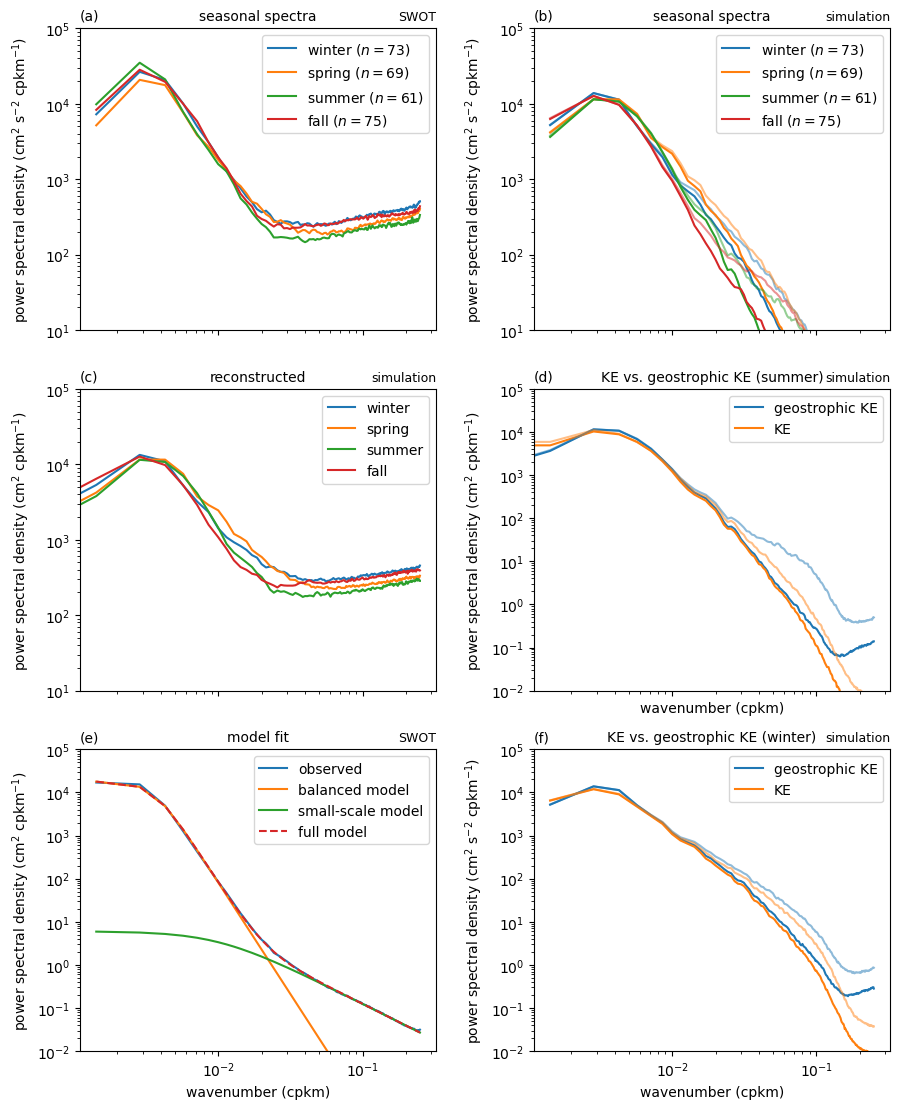

In [22]:
fig, ax = plt.subplots(3, 2, sharex=True, sharey=False, figsize=(figscale*6.5, figscale*8.0))

ax[0, 0].sharey(ax[0, 1])
for season, months in seasonal.items():
    df_season = spectra_tot_combined_GS[spectra_tot_combined_GS['month'].isin(months)]
    df_season_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
        ax[0,0].loglog(k_GS[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean[1:]*k_GS[1:]**2, label=f"{season} ($n = {len(df_season_sim)}$)")
ax[0,0].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[0,0].set_title('(a)',loc='left')
ax[0,0].set_title('seasonal spectra', loc='center')
ax[0,0].set_title('SWOT', loc='right',fontsize = 9)
ax[0,0].legend()
ax[0,0].set_ylim((1e1,10**5))

for season, months in seasonal.items():
    df_season_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'].isin(months)]
    df_season_sim_snapshots = ssha_tot_combined_GS_snapshots[ssha_tot_combined_GS_snapshots['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean_sim = np.mean(np.vstack(df_season_sim['spectra_simulation'].values), axis=0)
        seasonal_mean_sim_snapshots = np.mean(np.vstack(df_season_sim_snapshots['spectra_simulation'].values), axis=0)
        line, = ax[0,1].loglog(k_GS[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean_sim[1:]*k_GS[1:]**2, label=f"{season} ($n = {len(df_season_sim)}$)")    
        ax[0,1].loglog(k_GS[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean_sim_snapshots[1:]*k_GS[1:]**2, color=line.get_color(), alpha=0.5)
ax[0,1].set_title('(b)',loc='left')
ax[0,1].set_title('seasonal spectra', loc='center')
ax[0,1].set_title('simulation', loc='right',fontsize = 9)
ax[0,1].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[0,1].legend()
ax[0,1].set_ylim((1e1,10**5))


for i,row in reconstruct_sim_GS.iterrows():
    ax[1,0].loglog(k_GS*1e3,0.5*(2*np.pi)**2*(g/np.mean(f))**2*row['reconstruct_sim']*k_GS**2,label = row['season'])
ax[1,0].set_title('(c)',loc='left')
ax[1,0].set_title('reconstructed', loc='center')
ax[1,0].set_title('simulation', loc='right',fontsize = 9)
ax[1,0].legend()
ax[1,0].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[1,0].set_ylim((1e1,10**5))

line1,  = ax[1,1].loglog(k_GS*1e3,0.5*(2*np.pi)**2*summer_mean_kegeo,label = 'geostrophic KE')
line2,  = ax[1,1].loglog(k_GS*1e3,summer_mean_kesim,label = 'KE')
ax[1,1].loglog(k_GS*1e3,0.5*(2*np.pi)**2*summer_mean_kegeo_snapshots,color=line1.get_color(),alpha=0.5)
ax[1,1].loglog(k_GS*1e3,summer_mean_kesim_snapshots,color=line2.get_color(),alpha=0.5)
ax[1,1].set_xlabel('wavenumber (cpkm)')
ax[1,1].set_title('(d)',loc='left')
ax[1,1].set_title('KE vs. geostrophic KE (summer)', loc='center')
ax[1,1].set_title('simulation', loc='right',fontsize = 9)
ax[1,1].legend()
ax[1,1].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[1,1].set_ylim((10**-2,10**5))


ax[2,0].sharey(ax[2, 1])
ax[2,0].loglog(k_GS[1:]*1e3,mean_spectrum[1:], label='observed')
ax[2,0].loglog(k_GS[1:]*1e3,balanced_fit(k_GS[1:],*popcoef[0:3]),label = 'balanced model')
ax[2,0].loglog(k_GS[1:]*1e3,matern_spec_new(k_GS[1:],*popcoef[3:]),label = 'small-scale model')
ax[2,0].loglog(k_GS[1:]*1e3,matern_spec_new(k_GS[1:],*popcoef[3:])+balanced_fit(k_GS[1:],*popcoef[0:3]),'--',label = 'full model')#label = f"fit slope:{popcoef[2]:.2f}")
ax[2,0].legend()
ax[2,0].set_title('(e)',loc='left')
ax[2,0].set_title('model fit', loc='center')
ax[2,0].set_title('SWOT', loc='right',fontsize = 9)
ax[2,0].set_xlabel('wavenumber (cpkm)')
ax[2,0].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[2,0].set_ylim((10**-2,10**5))

line1,  = ax[2,1].loglog(k_GS[1:]*1e3,0.5*(2*np.pi)**2*winter_mean_kegeo[1:],label = 'geostrophic KE')
line2,  = ax[2,1].loglog(k_GS[1:]*1e3,winter_mean_kesim[1:],label = 'KE')
ax[2,1].loglog(k_GS[1:]*1e3, 0.5*(2*np.pi)**2*winter_mean_kegeo_snapshots[1:], color=line1.get_color(), alpha=0.5)
ax[2,1].loglog(k_GS[1:]*1e3, winter_mean_kesim_snapshots[1:], color=line2.get_color(), alpha=0.5)
ax[2,1].set_xlabel('wavenumber (cpkm)')
ax[2,1].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[2,1].set_title('(f)',loc='left')
ax[2,1].set_title('KE vs. geostrophic KE (winter)', loc='center')
ax[2,1].set_title('simulation', loc='right',fontsize = 9)
ax[2,1].legend()
ax[2,1].set_ylim((10**-2,10**5))

fig.align_ylabels()
fig.tight_layout(w_pad=2)
plt.savefig('spectra-gulfstream.pdf',dpi = 300)

### Figure 3 spectra and the fit Sargasso Sea

In [23]:
k_Ol = np.fft.rfftfreq(track_length, dx)
# load KE spectra in simulation for Sargasso Sea
KEsimspectra = np.load('data/KEsimdailymean_Oleander_new_swath_reselect_rotate_anom.npy',allow_pickle='TRUE').item()
for key, value in KEsimspectra.items():
    globals()[key] = value

# load KE spectra in simulation for Sargasso Sea snapshots
KEsimspectra_sp_rotate = np.load('data/KEsimdailymean_Oleander_new_swath_reselect_snapshots_rotate_anom.npy',allow_pickle='TRUE').item()
for key, value in KEsimspectra_sp_rotate.items():
    globals()[key] = value


with open('data/Oleander_reselect_sim_snapshots.pkl', 'rb') as f:
    data_Ol = pickle.load(f)
ssha_tot_combined_Ol_snapshots    = data_Ol['ssha_tot_combined']
    
mean_spectrum = np.mean(np.stack(spectra_tot_combined_Ol['spectrum'].values), axis=0)
Ainit = mean_spectrum[1]
popcoef,popcov = curve_fit(F_new, k_Ol[1:], np.log(mean_spectrum[1:]), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
                                        
g = 9.81
geoKE_spect_sim = np.zeros((ssha_tot_combined_Ol.shape[0],track_length//2 + 1))
for i, row in ssha_tot_combined_Ol.iterrows():
    day_indx = int(row['day_indx'])
    lat_swot = lat_strip_tot_Ol[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    ssh_spect_sim = row['spectra_simulation']
    geoKE_spect_sim[i,:] = (g/np.mean(f))**2*ssh_spect_sim*k_Ol**2 # geostrophic KE spectra 
geoKE_spect_sim_snapshots = np.zeros((ssha_tot_combined_Ol.shape[0],track_length//2 + 1))

for i, row in ssha_tot_combined_Ol_snapshots.iterrows():
    day_indx = int(row['day_indx'])
    lat_swot = lat_strip_tot_Ol[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    ssh_spect_sim = row['spectra_simulation']
    geoKE_spect_sim_snapshots[i,:] = (g/np.mean(f))**2*ssh_spect_sim*k_Ol**2 # geostrophic KE spectra 
    

KE_spectra_sim = 0.5*v_cross_spectra_sim
KE_spectra_sim_snapshots = 0.5*v_cross_spectra_sim_sp

ssha_tot_combined_Ol['geoKE_spect_sim'] = list(geoKE_spect_sim)
ssha_tot_combined_Ol['KE_spectra_sim'] = list(KE_spectra_sim)
ssha_tot_combined_Ol_snapshots['geoKE_spect_sim'] = list(geoKE_spect_sim_snapshots)
ssha_tot_combined_Ol_snapshots['KE_spectra_sim'] = list(KE_spectra_sim_snapshots)

df_winter = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(seasonal['winter'])]
winter_mean_kegeo = np.mean(np.vstack(df_winter['geoKE_spect_sim'].values), axis=0)
winter_mean_kesim = np.mean(np.vstack(df_winter['KE_spectra_sim'].values), axis=0)

df_winter_snapshots = ssha_tot_combined_Ol_snapshots[ssha_tot_combined_Ol_snapshots['month'].isin(seasonal['winter'])]
winter_mean_kegeo_snapshots = np.mean(np.vstack(df_winter_snapshots['geoKE_spect_sim'].values), axis=0)
winter_mean_kesim_snapshots = np.mean(np.vstack(df_winter_snapshots['KE_spectra_sim'].values), axis=0)

df_summer = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(seasonal['summer'])]
summer_mean_kegeo = np.mean(np.vstack(df_summer['geoKE_spect_sim'].values), axis=0)
summer_mean_kesim = np.mean(np.vstack(df_summer['KE_spectra_sim'].values), axis=0)

df_summer_snapshots = ssha_tot_combined_Ol_snapshots[ssha_tot_combined_Ol_snapshots['month'].isin(seasonal['summer'])]
summer_mean_kegeo_snapshots = np.mean(np.vstack(df_summer_snapshots['geoKE_spect_sim'].values), axis=0)
summer_mean_kesim_snapshots = np.mean(np.vstack(df_summer_snapshots['KE_spectra_sim'].values), axis=0)

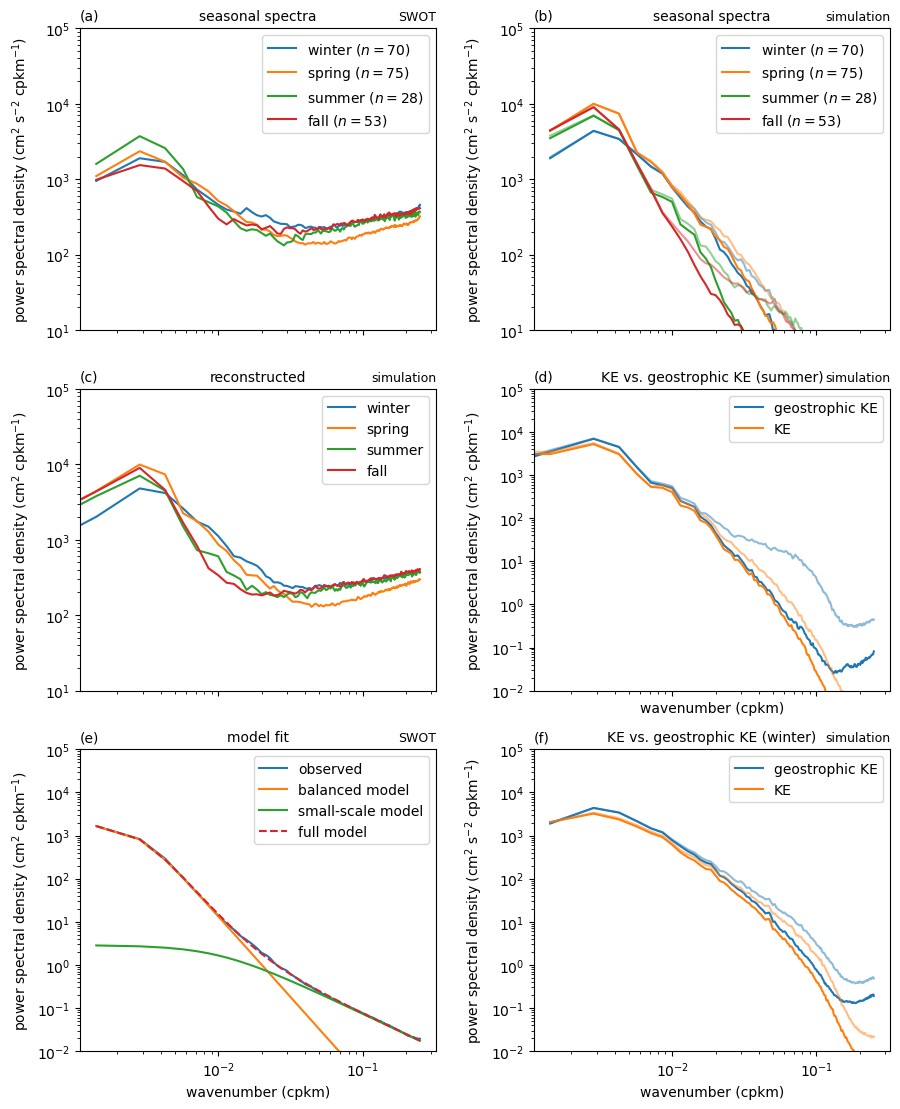

In [24]:
fig, ax = plt.subplots(3, 2, sharex=True, sharey=False, figsize=(figscale*6.5, figscale*8.0))
ax[0, 0].sharey(ax[0, 1])
for season, months in seasonal.items():
    df_season = spectra_tot_combined_Ol[spectra_tot_combined_Ol['month'].isin(months)]
    df_season_sim = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
        ax[0,0].loglog(k_Ol[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean[1:]*k_Ol[1:]**2, label=f"{season} ($n = {len(df_season_sim)}$)")
ax[0,0].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[0,0].set_title('(a)',loc='left')
ax[0,0].set_title('seasonal spectra', loc='center')
ax[0,0].set_title('SWOT', loc='right',fontsize = 9)
ax[0,0].legend()
ax[0,0].set_ylim((1e1,10**5))

for season, months in seasonal.items():
    df_season_sim = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'].isin(months)]
    df_season_sim_snapshots = ssha_tot_combined_Ol_snapshots[ssha_tot_combined_Ol_snapshots['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean_sim = np.mean(np.vstack(df_season_sim['spectra_simulation'].values), axis=0)
        seasonal_mean_sim_snapshots = np.mean(np.vstack(df_season_sim_snapshots['spectra_simulation'].values), axis=0)
        line, = ax[0,1].loglog(k_Ol[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean_sim[1:]*k_Ol[1:]**2, label=f"{season} ($n = {len(df_season_sim)}$)")    
        ax[0,1].loglog(k_Ol[1:]*1e3, 0.5*(2*np.pi)**2*(g/np.mean(f))**2*seasonal_mean_sim_snapshots[1:]*k_Ol[1:]**2, color=line.get_color(), alpha=0.5)
ax[0,1].set_title('(b)',loc='left')
ax[0,1].set_title('seasonal spectra', loc='center')
ax[0,1].set_title('simulation', loc='right',fontsize = 9)
ax[0,1].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[0,1].legend()
ax[0,1].set_ylim((1e1,10**5))


for i,row in reconstruct_sim_Ol.iterrows():
    ax[1,0].loglog(k_Ol*1e3,0.5*(2*np.pi)**2*(g/np.mean(f))**2*row['reconstruct_sim']*k_Ol**2,label = row['season'])
ax[1,0].set_title('(c)',loc='left')
ax[1,0].set_title('reconstructed', loc='center')
ax[1,0].set_title('simulation', loc='right',fontsize = 9)
ax[1,0].legend()
ax[1,0].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[1,0].set_ylim((1e1,10**5))

ax[1,0].set_title('(c)',loc='left')
ax[1,0].set_title('reconstructed', loc='center')
ax[1,0].set_title('simulation', loc='right',fontsize = 9)
ax[1,0].legend()
ax[1,0].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[1,0].set_ylim((1e1,10**5))

line1,  = ax[1,1].loglog(k_Ol*1e3,0.5*(2*np.pi)**2*summer_mean_kegeo,label = 'geostrophic KE')
line2,  = ax[1,1].loglog(k_Ol*1e3,summer_mean_kesim,label = 'KE')
ax[1,1].loglog(k_Ol*1e3,0.5*(2*np.pi)**2*summer_mean_kegeo_snapshots,color=line1.get_color(),alpha=0.5)
ax[1,1].loglog(k_Ol*1e3,summer_mean_kesim_snapshots,color=line2.get_color(),alpha=0.5)
ax[1,1].set_xlabel('wavenumber (cpkm)')
ax[1,1].set_title('(d)',loc='left')
ax[1,1].set_title('KE vs. geostrophic KE (summer)', loc='center')
ax[1,1].set_title('simulation', loc='right',fontsize = 9)
ax[1,1].legend()
ax[1,1].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[1,1].set_ylim((10**-2,10**5))


ax[2,0].sharey(ax[1, 1])
ax[2,0].loglog(k_Ol[1:]*1e3,mean_spectrum[1:], label='observed')
ax[2,0].loglog(k_Ol[1:]*1e3,balanced_fit(k_Ol[1:],*popcoef[0:3]),label = 'balanced model')
ax[2,0].loglog(k_Ol[1:]*1e3,matern_spec_new(k_Ol[1:],*popcoef[3:]),label = 'small-scale model')
ax[2,0].loglog(k_Ol[1:]*1e3,matern_spec_new(k_Ol[1:],*popcoef[3:])+balanced_fit(k_Ol[1:],*popcoef[0:3]),'--',label = 'full model')#label = f"fit slope:{popcoef[2]:.2f}")
ax[2,0].legend()
ax[2,0].set_title('(e)',loc='left')
ax[2,0].set_title('model fit', loc='center')
ax[2,0].set_title('SWOT', loc='right',fontsize = 9)
ax[2,0].set_xlabel('wavenumber (cpkm)')
ax[2,0].set_ylabel('power spectral density (cm$^2$ cpkm$^{-1}$)')
ax[2,0].set_ylim((10**-2,10**5))

line1, = ax[2,1].loglog(k_Ol[1:]*1e3,0.5*(2*np.pi)**2*winter_mean_kegeo[1:], label = 'geostrophic KE')
line2, = ax[2,1].loglog(k_Ol[1:]*1e3,winter_mean_kesim[1:], label = 'KE')
ax[2,1].loglog(k_Ol[1:]*1e3, 0.5*(2*np.pi)**2*winter_mean_kegeo_snapshots[1:], color=line1.get_color(), alpha=0.5)
ax[2,1].loglog(k_Ol[1:]*1e3, winter_mean_kesim_snapshots[1:], color=line2.get_color(), alpha=0.5)
ax[2,1].set_xlabel('wavenumber (cpkm)')
ax[2,1].set_ylabel('power spectral density (cm$^2$ s$^{-2}$ cpkm$^{-1}$)')
ax[2,1].set_title('(f)',loc='left')
ax[2,1].set_title('KE vs. geostrophic KE (winter)', loc='center')
ax[2,1].set_title('simulation', loc='right',fontsize = 9)
ax[2,1].legend()
ax[2,1].set_ylim((10**-2,10**5))
fig.align_ylabels()
fig.tight_layout(w_pad=2)
plt.savefig('spectra-sargasso.pdf',dpi = 300)

## Figure 4 Monthly slope 


In [25]:
slopedata = np.load('data/GSExtension_monthlyslope_reselect.npy',allow_pickle='TRUE').item()
for key, value in slopedata.items():
    globals()[key] = value


In [26]:
slopedataol = np.load('data/Oleander_monthlyslope_reselect.npy',allow_pickle='TRUE').item()
for key, value in slopedataol.items():
    globals()[key] = value

In [27]:
keslope = np.load('data/KEmonthlyslope.npy', allow_pickle=True).item()
for key, value in keslope.items():
    globals()[key] = value

# load slope uncertainties  
slopeun = np.load('data/slopeuncertains_reselect_rotate_anom.npy',allow_pickle='TRUE').item()
for key, value in slopeun.items():
    globals()[key] = value

slopeun_sp = np.load('data/slope_reconstructed_synthetic.npy',allow_pickle = 'TRUE').item()
for key,value in slopeun_sp.items():
    globals()[key] = value

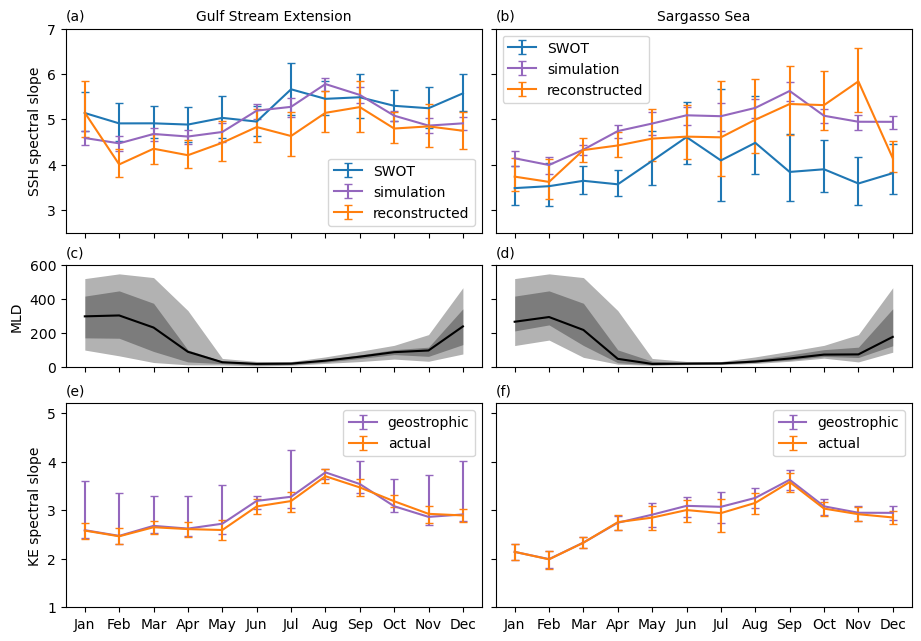

In [29]:
months_idx[8] = 'Sep'

fig = plt.figure(figsize=(figscale*6.5, figscale*4.5), constrained_layout=True)
gs = gridspec.GridSpec(
    3, 2,
    figure=fig,
    height_ratios=[1, 0.5, 1],
    width_ratios=[1, 1]
)
ax1 = fig.add_subplot(gs[0, 0])

ax1.errorbar(range(1,13), slopemonthly_GS, np.vstack([slopemonthly_GS - lowermGS, uppermGS - slopemonthly_GS]),
             ls = '-',capsize=3, label='SWOT')
ax1.errorbar(range(1,13), slopemonthly_sim_GS, np.vstack([slopemonthly_sim_GS - lowerm_simGS, upperm_simGS - slopemonthly_sim_GS]),
             ls = '-',capsize=3, color='C4', label='simulation')
ax1.errorbar(range(1,13), slopemonthly_simGSnz, np.vstack([slopemonthly_simGSnz - lowerm_simGSnz, upperm_simGSnz - slopemonthly_simGSnz]),
             ls = '-',capsize=3, label='reconstructed')

ax1.set_ylabel('SSH spectral slope')
ax1.set_ylim((2.5, 7))
ax1.set_xticks(range(1,13))
ax1.set_xticklabels([])
# ax1.set_xticklabels(months_idx)
ax1.legend(loc=4)
ax1.set_title('(a)',loc = 'left')
ax1.set_title('Gulf Stream Extension',loc = 'center')


ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(range(1,13), slopemonthly_Ol, np.vstack([slopemonthly_Ol - lowermOl, uppermOl - slopemonthly_Ol]),
             ls='-', capsize=3,label='SWOT')
ax2.errorbar(range(1,13), slopemonthly_sim_Ol, np.vstack([slopemonthly_sim_Ol - lowerm_simOl, upperm_simOl - slopemonthly_sim_Ol]),
             ls='-', capsize=3,color='C4', label='simulation')
ax2.errorbar(range(1,13), slopemonthly_simOlnz, np.vstack([slopemonthly_simOlnz - lowerm_simOlnz, upperm_simOlnz - slopemonthly_simOlnz]),
             ls = '-',capsize=3, label='reconstructed')

# ax2.set_ylabel('SSH spectral slope')
ax2.set_yticklabels([])
ax2.set_ylim((2.5, 7))
ax2.set_xticks(range(1,13))
ax2.set_xticklabels([])
ax2.legend(loc=2)
ax2.set_title('(b)',loc = 'left')
ax2.set_title('Sargasso Sea',loc = 'center')


ax3 = fig.add_subplot(gs[1, 0])
ax3.fill_between(range(1,13), mld_monthly_GS_p5, mld_monthly_GS_p95,color='black', alpha=0.3, label='5–95 percentile', linewidths=0)
ax3.fill_between(range(1,13), mld_monthly_GS_p25, mld_monthly_GS_p75,color='black', alpha=0.3, label='25–75 percentile', linewidths=0)
ax3.plot(range(1,13), mld_monthly_clim_GS, color='black')
ax3.set_xticks(range(1,13))
ax3.set_ylabel('MLD')
ax3.set_xticklabels([])
ax3.set_ylim((0, 600))
# ax3.legend(loc='upper right', bbox_to_anchor=(0.9, 0.97))
ax3.set_title('(c)',loc = 'left')


ax4 = fig.add_subplot(gs[1, 1])
ax4.fill_between(range(1,13), mld_monthly_Ol_p5, mld_monthly_GS_p95,color='black', alpha=0.3, label='5–95 percentile', linewidths=0)
ax4.fill_between(range(1,13), mld_monthly_Ol_p25, mld_monthly_GS_p75,color='black', alpha=0.3, label='25–75 percentile', linewidths=0)
ax4.plot(range(1,13), mld_monthly_clim_Ol, color='black')
ax4.set_xticks(range(1,13))
ax4.set_xticklabels([])
ax4.set_ylim((0, 600))
# ax4.legend(loc='upper right', bbox_to_anchor=(0.9, 0.97))
ax4.set_yticklabels([])
ax4.set_title('(d)',loc = 'left')

ax5 = fig.add_subplot(gs[2, 0])
ax5.errorbar(range(1,13),slopemonthly_sim_GS-2,\
             np.vstack([slopemonthly_sim_GS - lowerm_simGS, uppermGS - slopemonthly_sim_GS]),\
             capsize=3,label = 'geostrophic', color='C4')
# ax5.errorbar(range(1,13),slopemonthlyke_sim_GS,\
#              np.vstack([slopemonthlyke_sim_GS - lowerm_KE_GS, upperm_KE_GS - slopemonthlyke_sim_GS]),\
#              ls='-',capsize=3,label = 'actual', color='C1')
ax5.errorbar(range(1,13),slopemonthly_sp_sim_KE_GS,\
             np.vstack([slopemonthly_sp_sim_KE_GS - lowerm_KE_GS, upperm_KE_GS - slopemonthly_sp_sim_KE_GS]),\
             ls='-',capsize=3,label = 'actual', color='C1')
ax5.set_xticks(range(1,13))
ax5.set_xticklabels(months_idx)
ax5.legend()
ax5.set_ylabel('KE spectral slope')
ax5.set_ylim((1, 5.2))
ax5.set_xticklabels(months_idx)
ax5.set_title('(e)',loc = 'left')


ax6 = fig.add_subplot(gs[2, 1])

ax6.errorbar(range(1,13),slopemonthly_sim_Ol-2,\
             np.vstack([slopemonthly_sim_Ol - lowerm_simOl, upperm_simOl - slopemonthly_sim_Ol]), \
             capsize=3,label = 'geostrophic', color='C4')

ax6.errorbar(range(1,13),slopemonthly_sp_sim_KE_Ol,\
             np.vstack([slopemonthly_sp_sim_KE_Ol - lowerm_KE_Ol, upperm_KE_Ol - slopemonthly_sp_sim_KE_Ol]),\
             ls='-',capsize=3,label = 'actual', color='C1')
ax6.set_xticks(range(1,13))
ax6.set_xticklabels(months_idx)
ax6.set_ylim((1, 5.2))
ax6.set_yticklabels([])
ax6.set_title('(f)',loc = 'left')
ax6.legend()

plt.savefig('monthlyslopes.pdf',dpi = 300)


### Kinetic Energy budget


In [6]:
KEbudget = np.load('data/KE_plots.npy',allow_pickle='TRUE').item()
for key, value in KEbudget.items():
    globals()[key] = value

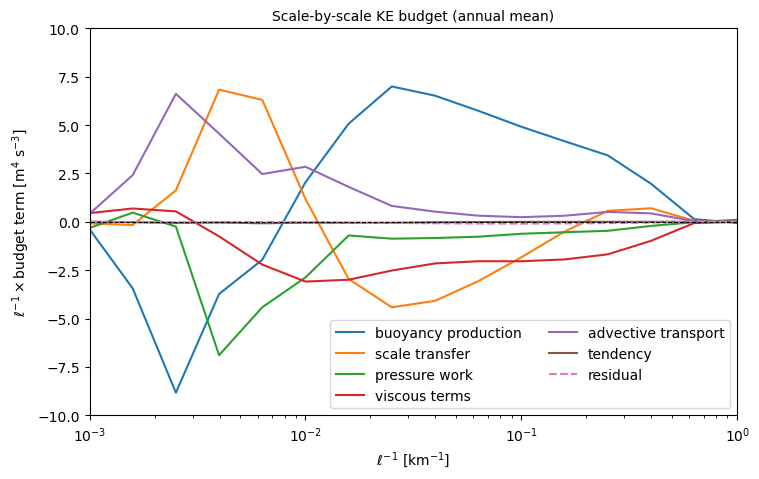

In [7]:
plt.figure(figsize=(figscale*5.5, figscale*3.5))
k_ls = k_ls/1e3
plt.semilogx(1e3*k_ls, db_dk*k_ls, label = 'buoyancy production')
plt.semilogx(1e3*k_ls, dpi_dk*k_ls,label = 'scale transfer')
plt.semilogx(1e3*k_ls, dpw_dk*k_ls, label = 'pressure work')
plt.semilogx(1e3*k_ls, dvis_dk*k_ls, label = 'viscous terms')
plt.semilogx(1e3*k_ls, dadvtrans_dk*k_ls, label = 'advective transport')
plt.semilogx(1e3*k_ls, dtend_dk*k_ls, label = 'tendency')
# plt.semilogx(1e3*k_ls,dext_dk*k_ls,label = 'wind work')
plt.semilogx(1e3*k_ls, dres_dk*k_ls, ls = 'dashed' ,label = 'residual')
plt.semilogx(1e3*k_ls, np.zeros(l_ls.shape), linewidth=0.8,linestyle='dashed',color = 'k')
plt.title('Scale-by-scale KE budget (annual mean)')
# plt.grid()
plt.legend(ncol=2)
plt.xlim(1e-3, 1)
plt.ylim(-10, 10)
plt.xlabel('$\\ell^{-1}$ [km$^{-1}$]')
plt.ylabel('$\\ell^{-1} \\times \\text{budget term}$ [m$^{4}$ s$^{-3}]$')
plt.tight_layout()
plt.savefig('kebudget-mean.pdf',dpi = 300)


In [39]:
db_dk[16]*k_ls[16]

-1.9660873807703223

In [40]:
1/(k_ls[15]*1e3)

100.0

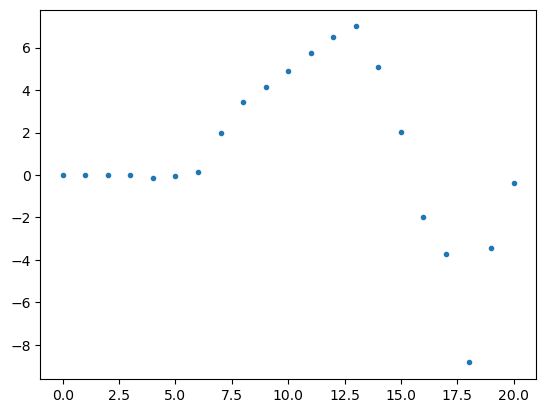

In [32]:
plt.plot(db_dk*k_ls,'.')

In [8]:
1e3*k_ls

array([1.00000000e+01, 6.30957344e+00, 3.98107171e+00, 2.51188643e+00,
       1.58489319e+00, 1.00000000e+00, 6.30957344e-01, 3.98107171e-01,
       2.51188643e-01, 1.58489319e-01, 1.00000000e-01, 6.30957344e-02,
       3.98107171e-02, 2.51188643e-02, 1.58489319e-02, 1.00000000e-02,
       6.30957344e-03, 3.98107171e-03, 2.51188643e-03, 1.58489319e-03,
       1.00000000e-03])

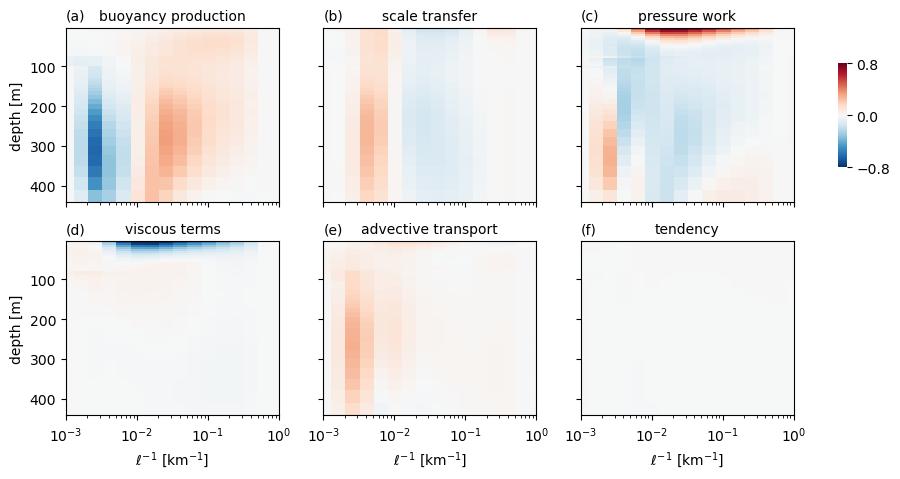

In [33]:
lyr1 = 0
lyr2 = 43
fig, axes = plt.subplots(
    nrows=2, ncols=4,
    figsize=(figscale*6.5, figscale*3.5),
#    sharex=True,
#    sharey=True,
    gridspec_kw=dict(width_ratios=(1, 1, 1, 0.04))
)

vmax = 0.8

cl1 = axes[0,0].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], db_dk_pf*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,0].set_title('buoyancy production')
axes[0,0].set_xscale("log")
axes[0,0].set_title('(a)',loc = 'left')
axes[0,0].set_ylabel('depth [m]')

cl2 = axes[0,1].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dpi_dk_pf*k_ls,shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,1].set_title('scale transfer')
axes[0,1].set_xscale("log")
axes[0,1].set_title('(b)',loc = 'left')

cl3 = axes[0,2].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dpw_dk_pf*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,2].set_title('pressure work')
axes[0,2].set_xscale("log")
axes[0,2].set_title('(c)',loc = 'left')

cb = plt.colorbar(cl3, cax=axes[0,3], ticks=np.linspace(-vmax, vmax, 3))
cb.outline.set_visible(False)

cl4 = axes[1,0].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dvis_dk_pf*k_ls,shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,0].set_title('viscous terms')
axes[1,0].set_xscale("log")
axes[1,0].set_title('(d)',loc = 'left')
axes[1,0].set_xlabel('$\\ell^{-1}$ [km$^{-1}$]')
axes[1,0].set_ylabel('depth [m]')

cl5 = axes[1,1].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dadvtrans_dk_pf*k_ls,shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,1].set_title('advective transport')
axes[1,1].set_xscale("log")
axes[1,1].set_title('(e)',loc = 'left')
axes[1,1].set_xlabel('$\\ell^{-1}$ [km$^{-1}$]')

cl6 = axes[1,2].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dtend_dk_pf*k_ls,shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,2].set_title('tendency')
axes[1,2].set_xscale("log")
axes[1,2].set_title('(f)',loc = 'left')
axes[1,2].set_xlabel('$\\ell^{-1}$ [km$^{-1}$]')

for i in range(2):
    for j in range(3):
        axes[i,j].yaxis.set_inverted(True)
        axes[i,j].set_xlim(1e-3, 1)

axes[0,0].tick_params(labelbottom=False)
axes[0,1].tick_params(labelbottom=False)
axes[0,2].tick_params(labelbottom=False)
axes[0,1].tick_params(labelleft=False)
axes[0,2].tick_params(labelleft=False)
axes[1,1].tick_params(labelleft=False)
axes[1,2].tick_params(labelleft=False)

axes[1,3].set_visible(False)

plt.tight_layout()

pos = axes[0,3].get_position()
axes[0,3].set_position([pos.x0, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])

plt.savefig('kebudget-depth.pdf',dpi = 300)


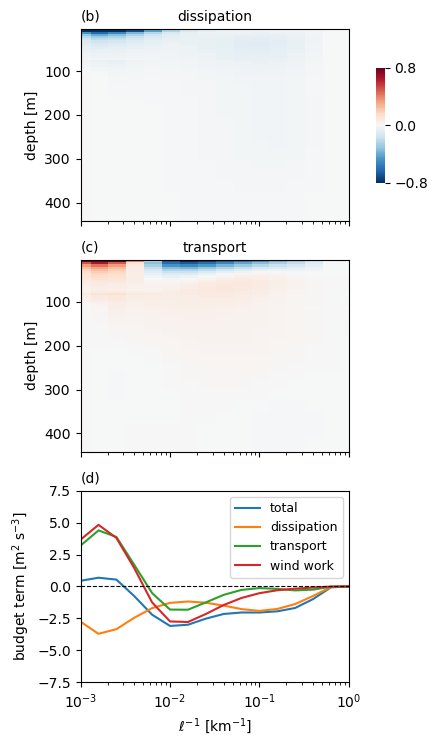

In [34]:
fig, axes = plt.subplots(
    nrows=3, ncols=2,
    gridspec_kw=dict(width_ratios=(1, 0.03)),
    figsize=(figscale*3.2, figscale*5.4),
    sharex='col',
)
# fig.suptitle("KE budget across scales Time-mean", fontsize=14)

vmax = 0.8

cl1 = axes[0,0].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dvertdis_dk_pf*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,0].set_xscale("log")
axes[0,0].set_title('(b)',loc = 'left')
axes[0,0].set_title('dissipation')
axes[0,0].set_ylabel('depth [m]')

cb = plt.colorbar(cl1, cax=axes[0,1], ticks=np.linspace(-vmax, vmax, 3))
cb.outline.set_visible(False)

cl2 = axes[1,0].pcolormesh(1e3*k_ls, -zc[lyr1+1:lyr2+1], dvertrans_dk_pf*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,0].set_xscale("log")
axes[1,0].set_title('(c)',loc = 'left')
axes[1,0].set_title('transport')
axes[1,0].set_ylabel('depth [m]')

axes[2,0].semilogx(1e3*k_ls, dvis_dk*k_ls, label = 'total')
axes[2,0].semilogx(1e3*k_ls, dvertdiss_dk*k_ls, label = 'dissipation')
axes[2,0].semilogx(1e3*k_ls, dvertrans_dk*k_ls, label = 'transport')
axes[2,0].semilogx(1e3*k_ls, dext_dk*k_ls,label = 'wind work')
axes[2,0].semilogx(1e3*k_ls, np.zeros(l_ls.shape), linewidth=0.8,linestyle='dashed',color = 'k')
axes[2,0].set_ylabel('budget term [m$^2$ s$^{-3}$]')
axes[2,0].set_title('(d)',loc = 'left')
axes[2,0].legend(fontsize = 9)
axes[2,0].set_xlabel('$\\ell^{-1}$ [km$^{-1}$]')
axes[2,0].set_ylim(-7.5, 7.5)

axes[0,0].set_xlim(1e-3, 1)
for i in range(2):
    axes[i,0].yaxis.set_inverted(True)
for i in range(1, 3):
    axes[i,1].set_visible(False)

plt.tight_layout()

pos = axes[0,1].get_position()
axes[0,1].set_position([pos.x0, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])

plt.savefig('kebudget-visc.pdf',dpi = 300)


In [35]:
t_month = np.arange(0,12)
months = ['Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul','Aug','Sep','Oct','Nov']


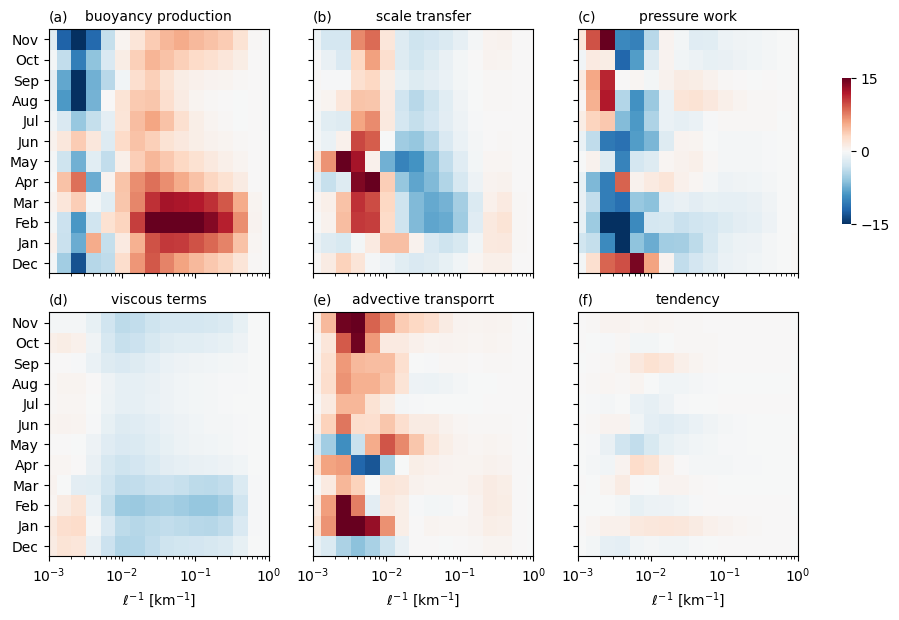

In [36]:
vmax = 15.0

fig, axes = plt.subplots(
    nrows=2, ncols=4,
    figsize=(figscale*6.5, figscale*4.5),
    gridspec_kw=dict(width_ratios=(1, 1, 1, 0.04))
)
# fig.suptitle("KE budget across scales Time-mean "+str(int(KE_tend.shape[0]/24)) + 'days', fontsize=14)
# fig.suptitle("KE budget across scales vertical mean", fontsize=14)

cl1 = axes[0,0].pcolormesh(1e3*k_ls, t_month, db_dk_monthly*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,0].set_title('buoyancy production')
axes[0,0].set_xscale("log")
axes[0,0].set_title('(a)',loc = 'left')

cl2 = axes[0,1].pcolormesh(1e3*k_ls, t_month, dpi_dk_monthly*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,1].set_title('scale transfer')
axes[0,1].set_xscale("log")
axes[0,1].set_title('(b)',loc = 'left')

cl3 = axes[0,2].pcolormesh(1e3*k_ls, t_month, dpw_dk_monthly*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[0,2].set_title('pressure work')
axes[0,2].set_xscale("log")
axes[0,2].set_title('(c)',loc = 'left')

cb = plt.colorbar(cl3, cax=axes[0,3], ticks=np.linspace(-vmax, vmax, 3))
cb.outline.set_visible(False)

cl4 = axes[1,0].pcolormesh(1e3*k_ls, t_month, dvis_dk_monthly*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,0].set_title('viscous terms')
axes[1,0].set_xscale("log")
axes[1,0].set_title('(d)', loc = 'left')

cl5 = axes[1,1].pcolormesh(1e3*k_ls, t_month, dadvtrans_dk_monthly*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,1].set_title('advective transporrt')
axes[1,1].set_xscale("log")
axes[1,1].set_title('(e)',loc = 'left')

cl6 = axes[1,2].pcolormesh(1e3*k_ls, t_month, dtend_dk_ts*k_ls, shading="auto",vmin = -vmax,vmax = vmax,rasterized=True,cmap = 'RdBu_r')
axes[1,2].set_title('tendency')
axes[1,2].set_xscale("log")
axes[1,2].set_title('(f)',loc = 'left')

for i in range(2):
    for j in range(3):
        axes[i,j].set_xlim(1e-3, 1)
        axes[i,j].set_yticks(t_month)
        if j == 0:
            axes[i,j].set_yticklabels(months)
        else:
            axes[i,j].tick_params(labelleft=False)
        if i == 1:
            axes[i,j].set_xlabel('$\\ell^{-1}$ [km$^{-1}$]')
        else:
            axes[i,j].tick_params(labelbottom=False)
axes[1,3].set_visible(False)

plt.tight_layout()

pos = axes[0,3].get_position()
axes[0,3].set_position([pos.x0, pos.y0 + 0.2*pos.height, pos.width, 0.6*pos.height])

plt.savefig('kebudget-season.pdf',dpi = 300)


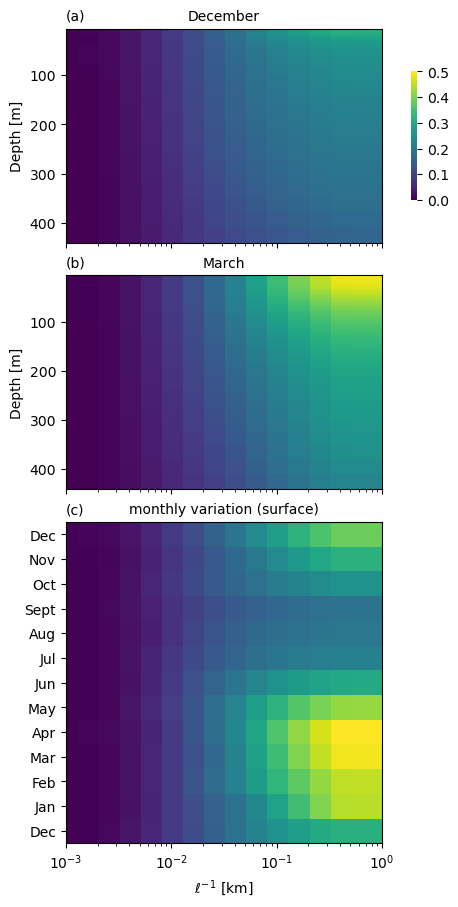

In [38]:
data = np.load('data/Rossbynumber_new.npz')
Romonthly = data['Romonthly']
t_month = np.arange(0,13)
months = ['Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul','Aug','Sept','Oct','Nov','Dec']
l_ls = np.logspace(2,6,21)
k_ls = (l_ls/1e3)**-1
layer = 0

fig, axes = plt.subplots(
    nrows=3, ncols=1,
    figsize=(figscale*3.2, figscale*6.4),
    sharex=True,
    constrained_layout=True,
    gridspec_kw=dict(height_ratios=(1, 1, 1.5))
)

cl1 = axes[0].pcolormesh((l_ls/1e3)**-1, -zc[1:44],Romonthly[0,:,:].T,shading="auto",vmin = 0,vmax = 0.5,rasterized=True)
axes[0].set_xscale("log")
axes[0].set_title('(a)',loc = 'left')
axes[0].set_title('December')
axes[0].set_ylabel('Depth [m]')
axes[0].yaxis.set_inverted(True)
axes[0].set_xlim(1e-3, 1)
axes[0].set_yticks(np.linspace(100, 400, 4))
cbar1 = plt.colorbar(cl1, shrink=0.6, fraction=0.15, ticks=np.linspace(0, 0.5, 6))
cbar1.outline.set_visible(False)


cl2 = axes[1].pcolormesh((l_ls/1e3)**-1, -zc[1:44],Romonthly[3,:,:].T,shading="auto",vmin = 0,vmax = 0.5,rasterized=True)
axes[1].set_xscale("log")
axes[1].set_title('(b)',loc = 'left')
axes[1].set_title('March')
axes[1].set_ylabel('Depth [m]')
axes[1].yaxis.set_inverted(True)
axes[1].set_yticks(np.linspace(100, 400, 4))


cl3 = axes[2].pcolormesh((l_ls/1e3)**-1,t_month,Romonthly[:,:,layer],shading="auto",vmin = 0,vmax = 0.5,rasterized=True)
axes[2].set_xscale("log")
axes[2].set_title('(c)',loc = 'left')
axes[2].set_title('monthly variation (surface)')
axes[2].set_yticks(t_month,months)

plt.xlabel('$\\ell^{-1}$ [km]')
plt.savefig('rossby.pdf',dpi = 300)
